In [9]:
import os
import time
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, Flatten, Dense, Dropout, LSTM, GRU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [10]:
path = r"..\Dataset\Processed\FD002"

In [11]:
X_train_fd2 = np.load(path + "\\x_train.npy")
X_test_fd2 = np.load(path + "\\x_test.npy")

y_train_fd2 = np.load(path + "\\y_train.npy")
y_test_fd2 = np.load(path + "\\y_test.npy")

X_val_fd2 = np.load(path + "\\x_val.npy")
y_val_fd2 = np.load(path + "\\y_val.npy")

# CNN Model

In [12]:
def build_cnn_baseline(input_shape=(30, 14)):
    """
    1D-CNN baseline model for temporal feature extraction across sensor channels.
    Uses Flatten() instead of GlobalAveragePooling1D() to preserve sequential degradation order.
    """
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        Conv1D(32, kernel_size=3, activation='relu', padding='same'),
        Flatten(),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1)
    ], name="CNN_Baseline")
    return model

tf.keras.utils.set_random_seed(42)
cnn_model = build_cnn_baseline(input_shape=(30, 14))
cnn_model.summary()

Model: "CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)                    │ (None, 30, 64)              │           2,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 30, 32)              │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 960)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 32)                  │          30,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 39,713 (155.13 KB)

 Trainable params: 39,713 (155.13 KB)

 Non-trainable params: 0 (0.00 B)

# LSTM Model

In [13]:
def build_lstm_baseline(input_shape=(30, 14)):
    """
    2-layer stacked LSTM baseline model for sequential degradation tracking.
    """
    model = Sequential([
        Input(shape=input_shape),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ], name="LSTM_Baseline")
    return model

tf.keras.utils.set_random_seed(42)
lstm_model = build_lstm_baseline(input_shape=(30, 14))
lstm_model.summary()

Model: "LSTM_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 30, 64)              │          20,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,729 (131.75 KB)

 Trainable params: 33,729 (131.75 KB)

 Non-trainable params: 0 (0.00 B)

# GRU Model

In [14]:
def build_gru_baseline(input_shape=(30, 14)):
    """
    2-layer stacked GRU baseline model with lower parameter footprint than LSTM.
    """
    model = Sequential([
        Input(shape=input_shape),
        GRU(64, return_sequences=True),
        Dropout(0.2),
        GRU(32, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ], name="GRU_Baseline")
    return model

tf.keras.utils.set_random_seed(42)
gru_model = build_gru_baseline(input_shape=(30, 14))
gru_model.summary()

Model: "GRU_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                          │ (None, 30, 64)              │          15,360 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_3 (GRU)                          │ (None, 32)                  │           9,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,857 (101.00 KB)

 Trainable params: 25,857 (101.00 KB)

 Non-trainable params: 0 (0.00 B)

# Training Configuration 

In [15]:
os.makedirs('../Models/FD002', exist_ok=True)
def train_baseline_model(model, X_tr, y_tr, X_va, y_va, model_name):
    """
    Unified training pipeline for baseline models with standardized hyperparameters.
    """
    tf.keras.utils.set_random_seed(42)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )
    
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
        ModelCheckpoint(f'../Models/FD002/{model_name}.keras', monitor='val_loss', save_best_only=True)
    ]
    
    start_time = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=100,
        batch_size=64,
        callbacks=callbacks,
        verbose=1
    )
    elapsed_time = time.time() - start_time
    print(f"Finished training {model_name} in {elapsed_time:.1f} seconds.")
    return history, elapsed_time

In [16]:
tf.keras.utils.set_random_seed(42)
hist_cnn,  time_cnn  = train_baseline_model(cnn_model,  X_train_fd2, y_train_fd2, X_val_fd2, y_val_fd2, 'cnn_baseline')

tf.keras.utils.set_random_seed(42)
hist_lstm, time_lstm = train_baseline_model(lstm_model, X_train_fd2, y_train_fd2, X_val_fd2, y_val_fd2, 'lstm_baseline')

tf.keras.utils.set_random_seed(42)
hist_gru,  time_gru  = train_baseline_model(gru_model,  X_train_fd2, y_train_fd2, X_val_fd2, y_val_fd2, 'gru_baseline')

Epoch 1/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 989.2830 - mae: 23.3028 - val_loss: 374.5517 - val_mae: 15.4816 - learning_rate: 0.0010
Epoch 2/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 437.7952 - mae: 16.2147 - val_loss: 297.9851 - val_mae: 13.3510 - learning_rate: 0.0010
Epoch 3/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 406.1570 - mae: 15.5031 - val_loss: 287.2281 - val_mae: 13.1242 - learning_rate: 0.0010
Epoch 4/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 388.5674 - mae: 15.0661 - val_loss: 281.8392 - val_mae: 12.8485 - learning_rate: 0.0010
Epoch 5/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 383.9111 - mae: 14.9181 - val_loss: 260.5652 - val_mae: 12.4563 - learning_rate: 0.0010
Epoch 6/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 373.1263 - mae: 14.6470 - val_loss: 270.8182 - val_mae: 12.7849 - learning_rate: 0.0010
Epoch 7/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 361.3787 - mae: 14.3719 - val_loss: 291.9329 

# Evaluation Metrics

In [17]:
def nasa_score(y_true, y_pred):
    """
    NASA PHM08 asymmetric scoring function.
    Late predictions (y_pred > y_true) penalize exponentially higher (e^(d/10)-1)
    than early predictions (y_pred < y_true) penalized as (e^(-d/13)-1).
    """
    errors = np.asarray(y_pred).flatten() - np.asarray(y_true).flatten()
    scores = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )
    return float(np.sum(scores))

In [18]:
def evaluate_model_performance(model, X_te, y_te, name="Model"):
    """
    Computes MAE, RMSE, and NASA Score simultaneously.
    """
    y_pred = model.predict(X_te).flatten()
    mae = float(mean_absolute_error(y_te, y_pred))
    rmse = float(np.sqrt(mean_squared_error(y_te, y_pred)))
    score = nasa_score(y_te, y_pred)
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "NASA Score": round(score, 1)}

print("Evaluation functions defined.")

Evaluation functions defined.


# Comparison Table

In [19]:
os.makedirs('../Results/comparison_tables', exist_ok=True)

# Compute performance across all three baselines
metrics_cnn  = evaluate_model_performance(cnn_model,  X_test_fd2, y_test_fd2, "CNN")
metrics_lstm = evaluate_model_performance(lstm_model, X_test_fd2, y_test_fd2, "LSTM")
metrics_gru  = evaluate_model_performance(gru_model,  X_test_fd2, y_test_fd2, "GRU")

metrics_cnn['Training Time (s)']  = round(time_cnn, 1)
metrics_lstm['Training Time (s)'] = round(time_lstm, 1)
metrics_gru['Training Time (s)']  = round(time_gru, 1)

baseline_comparison_df = pd.DataFrame([metrics_cnn, metrics_lstm, metrics_gru])
baseline_comparison_df.to_csv('../Results/comparison_tables/fd002_baseline_comparison.csv', index=False)
print("=== FD002 Baseline Model Performance Comparison ===")
print(baseline_comparison_df.to_string(index=False))


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step 
=== FD002 Baseline Model Performance Comparison ===
Model   MAE  RMSE  NASA Score  Training Time (s)
  CNN 11.04 14.77      1251.8               36.9
 LSTM 10.93 14.77      1138.4              120.2
  GRU 10.19 13.71       953.7              406.1


# Visualizations

# 1. Training & Validation Loss Curves

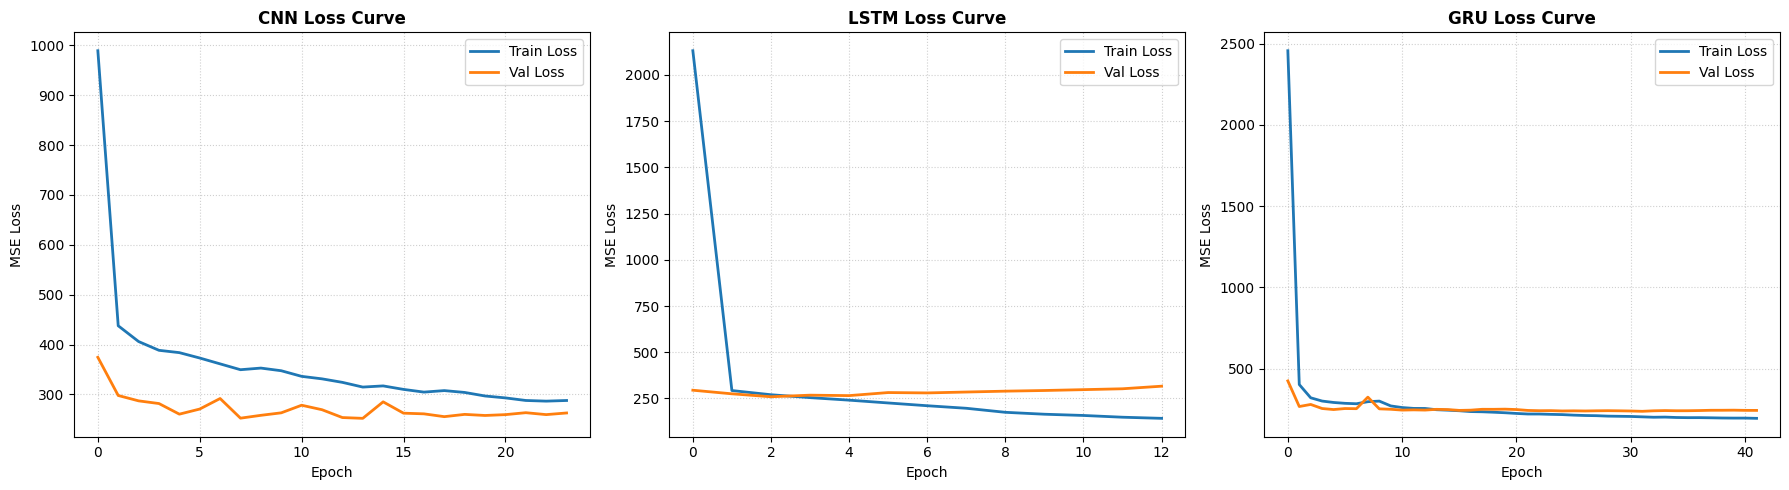

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_hist = [("CNN", hist_cnn), ("LSTM", hist_lstm), ("GRU", hist_gru)]
for i, (name, hist) in enumerate(models_hist):
    axes[i].plot(hist.history['loss'], label='Train Loss', lw=2)
    axes[i].plot(hist.history['val_loss'], label='Val Loss', lw=2)
    axes[i].set_title(f'{name} Loss Curve', fontweight='bold')
    axes[i].set_xlabel('Epoch'); axes[i].set_ylabel('MSE Loss')
    axes[i].legend(); axes[i].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('../Results/FD002_plots/training_loss_curves.png', dpi=200, bbox_inches='tight')

# 2. Actual vs Predicted RUL Scatter Plots

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


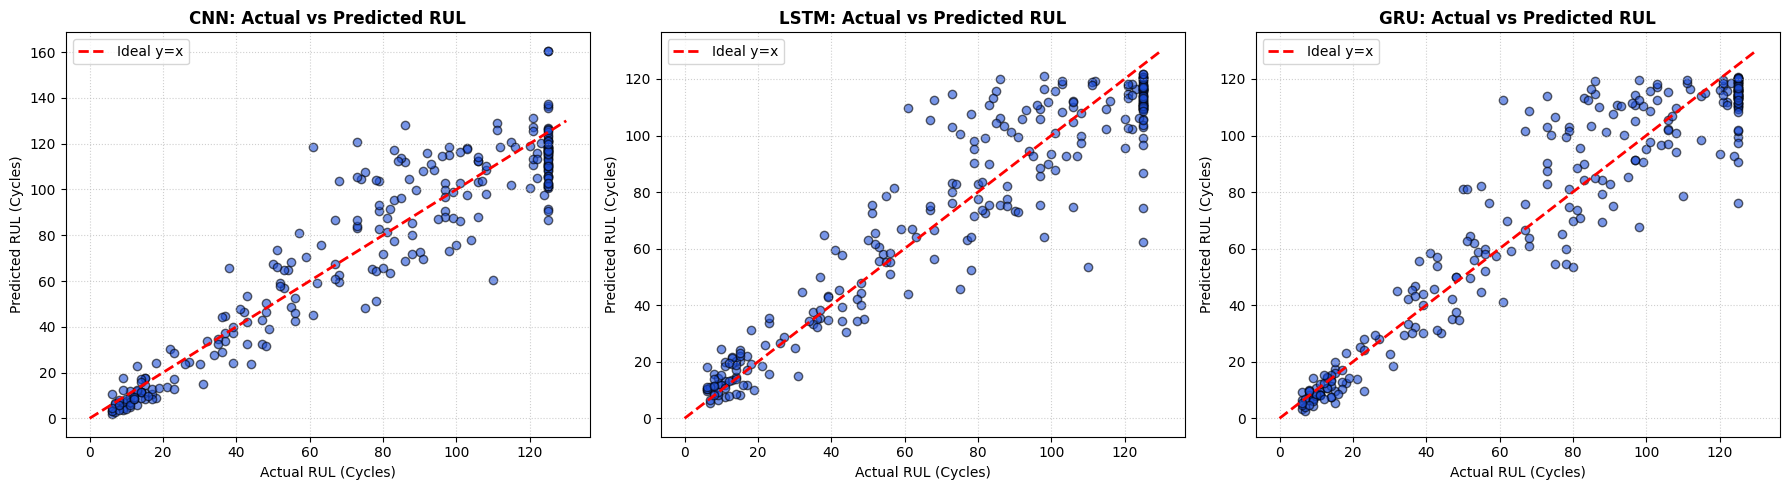

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
trained_models = [("CNN", cnn_model), ("LSTM", lstm_model), ("GRU", gru_model)]
for i, (name, mod) in enumerate(trained_models):
    y_pred = mod.predict(X_test_fd2).flatten()
    axes[i].scatter(y_test_fd2, y_pred, alpha=0.6, edgecolors='k', color='#1D4ED8')
    axes[i].plot([0, 130], [0, 130], 'r--', lw=2, label='Ideal y=x')
    axes[i].set_title(f'{name}: Actual vs Predicted RUL', fontweight='bold')
    axes[i].set_xlabel('Actual RUL (Cycles)'); axes[i].set_ylabel('Predicted RUL (Cycles)')
    axes[i].legend(); axes[i].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('../Results/FD002_plots/fd002_baseline_predictions_scatter.png', dpi=200, bbox_inches='tight')

# 3. Residual Error Distribution Histograms

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


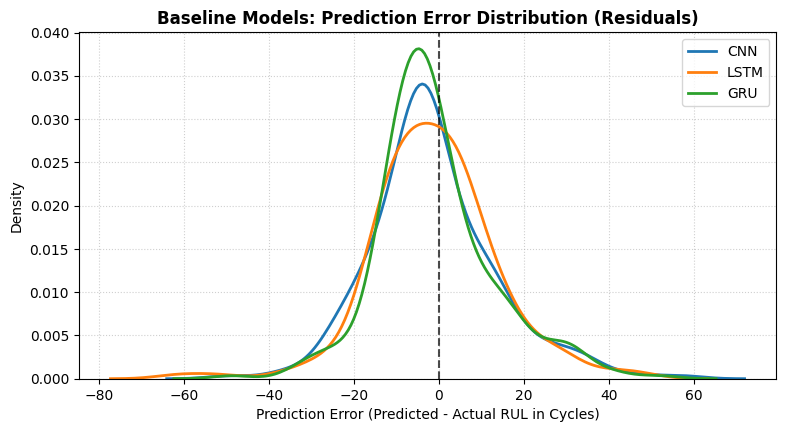

In [22]:
plt.figure(figsize=(9, 4.5))
for name, mod in trained_models:
    y_pred = mod.predict(X_test_fd2).flatten()
    residuals = y_pred - y_test_fd2
    sns.kdeplot(residuals, label=name, lw=2)
plt.axvline(0, color='k', linestyle='--', alpha=0.7)
plt.title("Baseline Models: Prediction Error Distribution (Residuals)", fontweight='bold')
plt.xlabel("Prediction Error (Predicted - Actual RUL in Cycles)"); plt.ylabel("Density")
plt.legend(); plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('../Results/FD002_plots/fd002_baseline_error_distribution.png', dpi=200, bbox_inches='tight')